# Parte Comum — Padronização, K-Means e Métricas

Dataset: **Obesity** (`data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv`)

## 0. Carregar o Dataset e Preparar Pastas de Saída

In [1]:
# [IA] Google Gemini – carregamento dos dados e importação das bibliotecas
# [IA] GitHub Copilot – estruturação standalone do notebook kmeans_metricas.ipynb e pasta de saída
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

caminho = Path("../../data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv")
out_dir = Path("../../out/parte_comum/kmeans")
out_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(caminho).drop_duplicates().reset_index(drop=True)
colunas_num = df.select_dtypes(include=[np.number]).columns.tolist()

print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Variáveis numéricas utilizadas no K-Means:", colunas_num)

Dataset carregado: 2087 linhas x 17 colunas
Variáveis numéricas utilizadas no K-Means: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


## 1. Transformação de Variáveis (Feature Transformation) e Padronização

### Separar o alvo, transformar as variáveis categóricas e padronizar todas as features

Como o K-Means não pode ter acesso aos rótulos reais durante o agrupamento, guardamos a coluna `NObeyesdad` separada (apenas para avaliação e métricas).

Para incluir todas as informações relevantes do dataset no agrupamento, aplicamos a transformação das variáveis categóricas antes da padronização:
- **Binárias (`yes`/`no`):** `family_history_with_overweight`, `FAVC`, `SMOKE` e `SCC` mapeadas para `0` (`no`) e `1` (`yes`).
- **Binária (`Gender`):** `Female` → `0`, `Male` → `1`.
- **Ordinais (`CAEC` e `CALC`):** preservando a ordem natural de frequência (`no` → `0`, `Sometimes` → `1`, `Frequently` → `2`, `Always` → `3`).
- **Nominal (`MTRANS`):** codificação *One-Hot* (`pd.get_dummies`).

Em seguida, aplicamos o `StandardScaler` sobre **todas as variáveis** (numéricas + categóricas transformadas) para colocá-las na mesma escala (média ≈ 0 e desvio padrão ≈ 1).

In [2]:
# [IA] Google Gemini – separação do alvo e padronização com StandardScaler
# [IA] GitHub Copilot – feature transformation de todas as variáveis categóricas antes do StandardScaler
y_real = df["NObeyesdad"].copy()
X = df.drop(columns=["NObeyesdad"]).copy()

# 1. Variáveis binárias yes/no -> 0/1
colunas_binarias = ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
for col in colunas_binarias:
    X[col] = X[col].map({"no": 0, "yes": 1})

# 2. Gender -> 0/1
X["Gender"] = X["Gender"].map({"Female": 0, "Male": 1})

# 3. Variáveis ordinais -> 0, 1, 2, 3
mapa_freq = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
for col in ["CAEC", "CALC"]:
    X[col] = X[col].map(mapa_freq)

# 4. Variável nominal (MTRANS) -> One-Hot Encoding
X = pd.get_dummies(X, columns=["MTRANS"], prefix="MTRANS", dtype=int)

assert X.isnull().sum().sum() == 0, "Existem valores nulos após a transformação!"

# Salvar resumo do pré-processamento
linhas_prep = []
for col in X.columns:
    if col in colunas_num:
        tipo = "Numérica + StandardScaler"
    elif col in colunas_binarias or col == "Gender":
        tipo = "Binária (0/1) + StandardScaler"
    elif col in ["CAEC", "CALC"]:
        tipo = "Ordinal (0-3) + StandardScaler"
    else:
        tipo = "OneHotEncoder (MTRANS) + StandardScaler"
    linhas_prep.append({"variavel": col, "preprocessamento": tipo})
pd.DataFrame(linhas_prep).to_csv(out_dir / "preprocessamento.csv", index=False)

# 5. Padronização (média = 0 e desvio padrão = 1) em todas as features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print(f"Total de features enviadas ao K-Means: {X_scaled.shape[1]}")
print("--- Conferência após padronização (média próxima de 0 e std próximo de 1) ---")
display(df_scaled.describe().T[["mean", "std", "min", "max"]].round(2))

Total de features enviadas ao K-Means: 20
--- Conferência após padronização (média próxima de 0 e std próximo de 1) ---


,mean,std,min,max
Gender,0.0,1.0,-1.01,0.99
Age,-0.0,1.0,-1.63,5.76
Height,0.0,1.0,-2.71,2.98
Weight,-0.0,1.0,-1.83,3.29
family_history_with_overweight,-0.0,1.0,-2.17,0.46
FAVC,-0.0,1.0,-2.75,0.36
FCVC,-0.0,1.0,-2.66,1.08
NCP,0.0,1.0,-2.23,1.70
CAEC,0.0,1.0,-2.49,4.04
SMOKE,0.0,1.0,-0.15,6.81


### Por que a padronização é necessária para o K-Means?

O algoritmo K-Means forma os grupos calculando a distância euclidiana entre os registros e os centroides.

No dataset *Obesity*, as variáveis estão em escalas muito diferentes: por exemplo, `Weight` varia de 39 a 173, enquanto `NCP` varia de 1 a 4 e as colunas binárias e do One-Hot valem só 0 ou 1. Sem padronizar os dados, as variáveis com escalas maiores dominariam o cálculo da distância, enquanto as de escala menor teriam peso irrelevante.

Ao aplicar o `StandardScaler` nas 20 variáveis (as 8 numéricas e as 12 colunas vindas das categóricas), todas passam a ter média igual a 0 e desvio-padrão igual a 1, de modo que nenhuma coluna domina a distância só por estar numa escala maior.

**Atenção:** a padronização iguala o peso de cada **coluna**, não de cada variável original. Como `MTRANS` virou 5 colunas no One-Hot, o meio de transporte entra na distância com o peso de cerca de 5 variáveis, e as categorias raras (por exemplo `MTRANS_Bike`, com 7 pessoas) ficam com valores padronizados muito altos (até 17 desvios-padrão). Esse efeito aparece nos clusters e é analisado na seção 3.5.

## 2. Agrupamento com K-Means

### 2.1 Passada 1 — `k` livre (Método do Cotovelo)

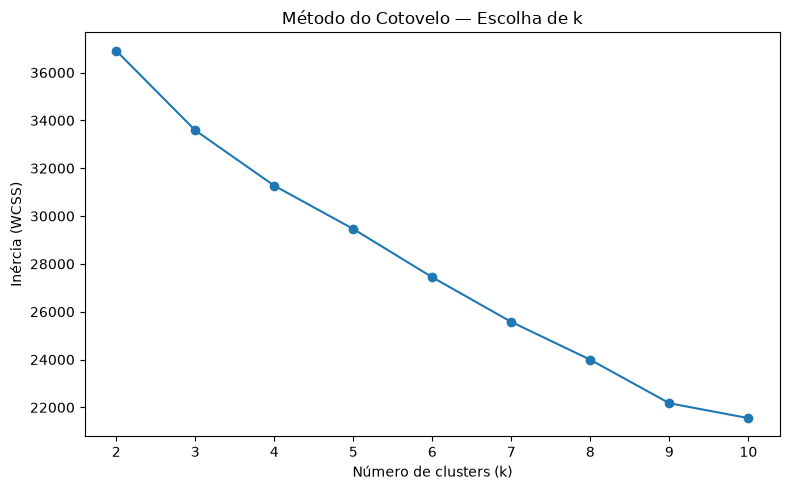

In [3]:
# [IA] Google Gemini – execução do K-Means para k de 2 a 10 e gráfico do Método do Cotovelo
valores_k = range(2, 11)
inercias = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

df_cotovelo = pd.DataFrame({"k": list(valores_k), "inercia": inercias})
df_cotovelo.to_csv(out_dir / "cotovelo.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.title("Método do Cotovelo — Escolha de k")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia (WCSS)")
plt.xticks(valores_k)
plt.tight_layout()
plt.savefig(out_dir / "cotovelo.png", dpi=150)
plt.show()

**Justificativa da escolha de `k_livre`:**

A curva não tem um cotovelo nítido. A inércia cai 9% de k = 2 para k = 3, 7% de 3 para 4 e, a partir daí, entre 6% e 8% a cada novo cluster (veja `cotovelo.csv`). Ou seja, depois de k = 4 cada cluster a mais traz um ganho parecido, sem um ponto em que a queda pare de forma clara.

Escolhemos k = 4 por ser o ponto em que as quedas se estabilizam e por manter um número pequeno de grupos, que ainda dá para interpretar. Como o cotovelo não é claro, essa escolha tem uma parte subjetiva, registrada nas limitações.

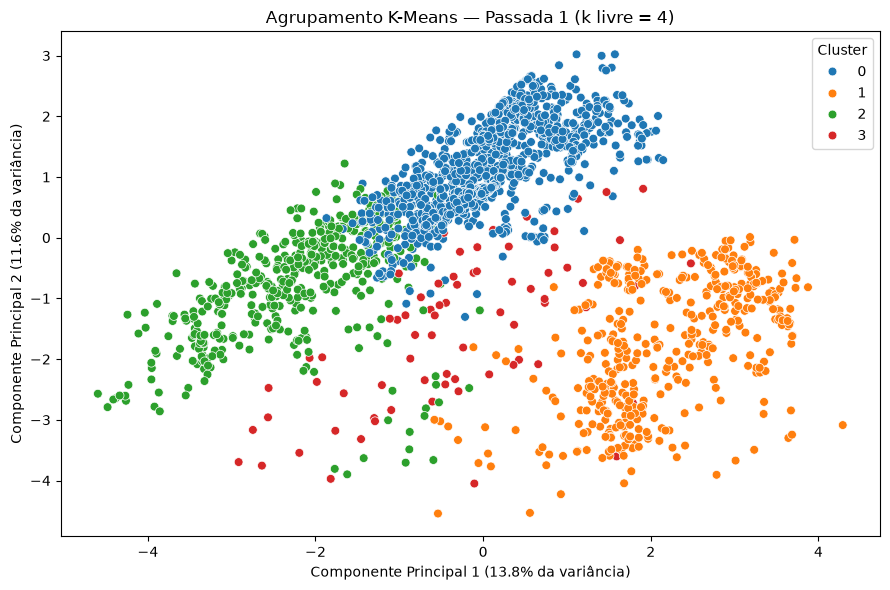

In [4]:
# [IA] Google Gemini – K-Means (Passada 1 com k livre) e projeção 2D via PCA
# [IA] GitHub Copilot – exibição da variância explicada pelo PCA e salvamento em out/parte_comum/kmeans/
k_livre = 4

kmeans_livre = KMeans(n_clusters=k_livre, random_state=42, n_init=10)
clusters_livre = kmeans_livre.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_livre, palette="tab10", s=40)
plt.title(f"Agrupamento K-Means — Passada 1 (k livre = {k_livre})")
plt.xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
plt.ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% da variância)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(out_dir / "clusters_livre.png", dpi=150)
plt.show()

### 2.2 Passada 2 — `k` fixo (número real de classes)

Número real de classes (k fixo): 7


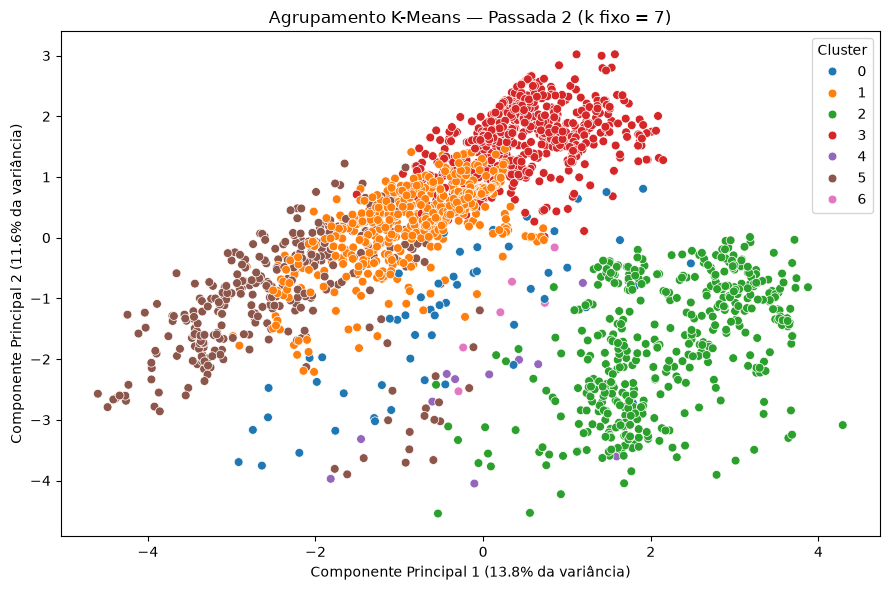

In [5]:
# [IA] Google Gemini – K-Means (Passada 2 com k fixo) e visualização na mesma projeção PCA
k_fixo = y_real.nunique()
print(f"Número real de classes (k fixo): {k_fixo}")

kmeans_fixo = KMeans(n_clusters=k_fixo, random_state=42, n_init=10)
clusters_fixo = kmeans_fixo.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_fixo, palette="tab10", s=40)
plt.title(f"Agrupamento K-Means — Passada 2 (k fixo = {k_fixo})")
plt.xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
plt.ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% da variância)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(out_dir / "clusters_fixo.png", dpi=150)
plt.show()

## 3. Métricas e Matriz de Confusão

Para cada passada:

1. Mapeamos cada cluster para a **classe real majoritária** dentro dele (o K-Means não conhece os rótulos; o mapeamento só é feito aqui, na avaliação).
2. Construímos a **matriz de confusão** entre o rótulo real (linhas) e o rótulo mapeado (colunas). Na Passada 1 a matriz é **retangular**: só existem 4 rótulos previstos possíveis para 7 classes reais. Na Passada 2 ela é **quadrada** (7 × 7); colunas zeradas indicam classes que nenhum cluster representa.
3. Calculamos **acurácia**, **precisão** e **recall** por classe diretamente da matriz:
   - acurácia = soma da diagonal / total;
   - precisão da classe *c* = acertos de *c* / total da coluna *c* (tudo que foi rotulado como *c*);
   - recall da classe *c* = acertos de *c* / total da linha *c* (tudo que realmente é *c*).

Dois detalhes:
- "Classe majoritária" significa a classe **mais frequente** dentro do cluster, não necessariamente mais da metade.
- Quando nenhum cluster recebe o nome de uma classe, a precisão dela é indefinida (0 ÷ 0). Nesses casos registramos 0, o que puxa a precisão média (macro) para baixo.

As classes são exibidas na ordem ordinal do IMC (de abaixo do peso até obesidade tipo III).

In [6]:
# [IA] Claude Code – funções de mapeamento cluster → classe majoritária, matriz de confusão e métricas por classe
from sklearn.metrics import confusion_matrix

ordem_classes = [
    "Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
    "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III",
]
assert set(ordem_classes) == set(y_real.unique())


def composicao_clusters(clusters, y):
    """Tabela cluster × classe real (contagens), base do mapeamento."""
    tab = pd.crosstab(pd.Series(clusters, name="cluster"), y.rename("classe real"))
    return tab[ordem_classes]


def mapear_clusters(composicao):
    """Associa cada cluster à classe real mais frequente dentro dele."""
    return composicao.idxmax(axis=1).to_dict()


def matriz_confusao(y, y_mapeado, colunas):
    """Linhas = classe real (todas), colunas = rótulos mapeados considerados."""
    mc = confusion_matrix(y, y_mapeado, labels=ordem_classes)
    mc = pd.DataFrame(mc, index=ordem_classes, columns=ordem_classes)
    mc.index.name, mc.columns.name = "real", "mapeado"
    return mc[colunas]


def metricas_da_matriz(mc_quadrada):
    """Acurácia global e precisão/recall por classe a partir de uma matriz 7 × 7."""
    m = mc_quadrada.loc[ordem_classes, ordem_classes].to_numpy()
    acertos = np.diag(m)
    total_coluna = m.sum(axis=0)   # previstos como a classe
    total_linha = m.sum(axis=1)    # realmente da classe
    precisao = np.divide(acertos, total_coluna, out=np.zeros(len(acertos)), where=total_coluna > 0)
    recall = np.divide(acertos, total_linha, out=np.zeros(len(acertos)), where=total_linha > 0)
    por_classe = pd.DataFrame({
        "suporte": total_linha,
        "previstos": total_coluna,
        "acertos": acertos,
        "precisao": precisao,
        "recall": recall,
    }, index=ordem_classes)
    acuracia = acertos.sum() / m.sum()
    return acuracia, por_classe


def plotar_matriz(mc, titulo, arquivo):
    plt.figure(figsize=(1.3 * mc.shape[1] + 4, 6))
    sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
    plt.title(titulo)
    plt.ylabel("Classe real")
    plt.xlabel("Rótulo mapeado (classe majoritária do cluster)")
    plt.tight_layout()
    plt.savefig(out_dir / arquivo, dpi=150)
    plt.show()

### 3.1 Passada 1 — `k` livre (k = 4)

Composição dos clusters (cluster × classe real):


classe real,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
cluster,,,,,,,
0,28,44,145,130,229,199,323
1,45,33,65,94,110,95,1
2,188,164,54,59,7,1,0
3,6,41,12,7,5,2,0


Mapeamento cluster → classe majoritária:


,classe mapeada,tamanho,% da classe majoritária
0,Obesity_Type_III,1098,29.4
1,Obesity_Type_I,443,24.8
2,Insufficient_Weight,473,39.7
3,Normal_Weight,73,56.2


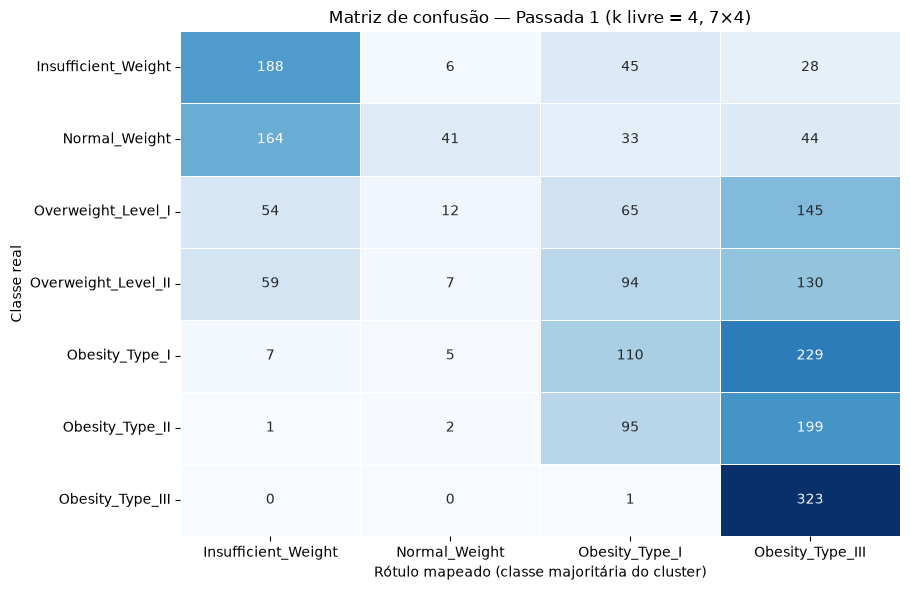

Acurácia (Passada 1): 0.317


,suporte,previstos,acertos,precisao,recall
Insufficient_Weight,267,473,188,0.397,0.704
Normal_Weight,282,73,41,0.562,0.145
Overweight_Level_I,276,0,0,0.000,0.000
Overweight_Level_II,290,0,0,0.000,0.000
Obesity_Type_I,351,443,110,0.248,0.313
Obesity_Type_II,297,0,0,0.000,0.000
Obesity_Type_III,324,1098,323,0.294,0.997


In [7]:
# [IA] Claude Code – mapeamento, matriz de confusão retangular e métricas da Passada 1
comp_livre = composicao_clusters(clusters_livre, y_real)
mapa_livre = mapear_clusters(comp_livre)
y_map_livre = pd.Series(clusters_livre).map(mapa_livre)

print("Composição dos clusters (cluster × classe real):")
display(comp_livre)
print("Mapeamento cluster → classe majoritária:")
display(pd.DataFrame({
    "classe mapeada": mapa_livre,
    "tamanho": comp_livre.sum(axis=1),
    "% da classe majoritária": (comp_livre.max(axis=1) / comp_livre.sum(axis=1) * 100).round(1),
}))

# Colunas = apenas os rótulos que algum cluster recebeu → matriz 7 × k (retangular)
colunas_livre = [c for c in ordem_classes if c in set(mapa_livre.values())]
mc_livre = matriz_confusao(y_real, y_map_livre, colunas_livre)
mc_livre.to_csv(out_dir / "matriz_confusao_livre.csv")
plotar_matriz(mc_livre, f"Matriz de confusão — Passada 1 (k livre = {k_livre}, {mc_livre.shape[0]}×{mc_livre.shape[1]})",
              "matriz_confusao_livre.png")

acc_livre, met_livre = metricas_da_matriz(matriz_confusao(y_real, y_map_livre, ordem_classes))
met_livre.to_csv(out_dir / "metricas_livre.csv")
print(f"Acurácia (Passada 1): {acc_livre:.3f}")
display(met_livre.style.format({"precisao": "{:.3f}", "recall": "{:.3f}"}))

### 3.2 Passada 2 — `k` fixo (k = 7)

Composição dos clusters (cluster × classe real):


classe real,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
cluster,,,,,,,
0,6,31,9,6,2,1,0
1,45,53,48,71,110,51,198
2,45,31,65,94,110,95,1
3,30,32,91,106,122,148,125
4,0,6,1,1,3,0,0
5,141,125,60,12,4,1,0
6,0,4,2,0,0,1,0


Mapeamento cluster → classe majoritária:


,classe mapeada,tamanho,% da classe majoritária
0,Normal_Weight,55,56.4
1,Obesity_Type_III,576,34.4
2,Obesity_Type_I,441,24.9
3,Obesity_Type_II,654,22.6
4,Normal_Weight,11,54.5
5,Insufficient_Weight,343,41.1
6,Normal_Weight,7,57.1


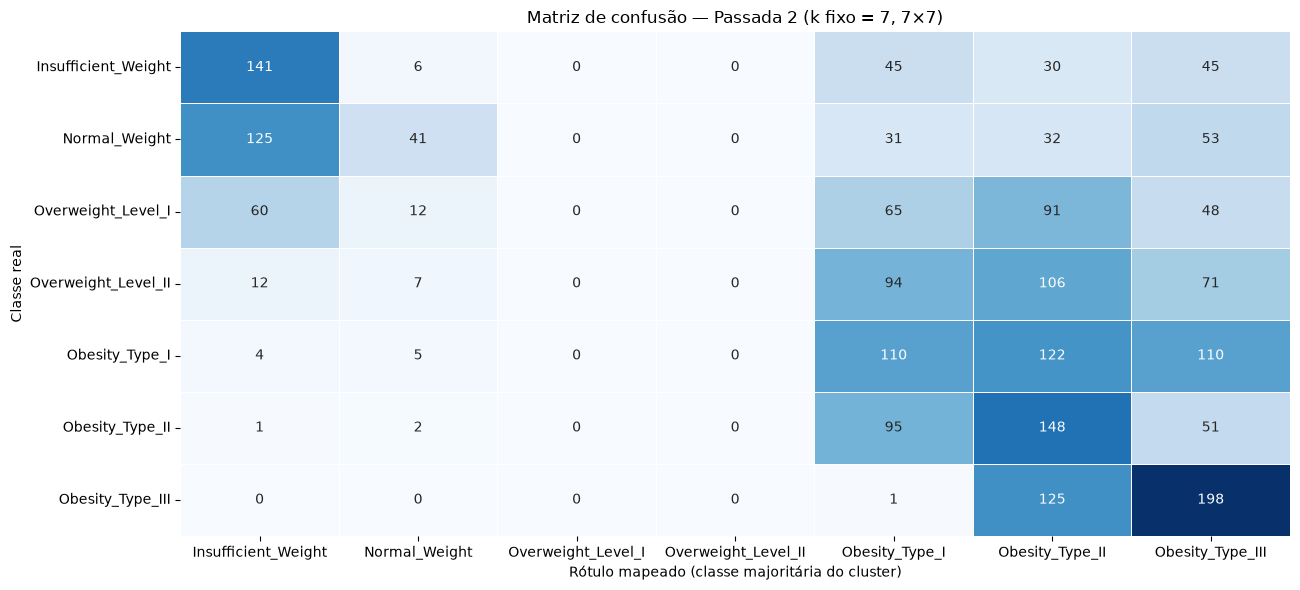

Acurácia (Passada 2): 0.306


,suporte,previstos,acertos,precisao,recall
Insufficient_Weight,267,343,141,0.411,0.528
Normal_Weight,282,73,41,0.562,0.145
Overweight_Level_I,276,0,0,0.000,0.000
Overweight_Level_II,290,0,0,0.000,0.000
Obesity_Type_I,351,441,110,0.249,0.313
Obesity_Type_II,297,654,148,0.226,0.498
Obesity_Type_III,324,576,198,0.344,0.611


Classes que nenhum cluster representa na Passada 2: ['Overweight_Level_I', 'Overweight_Level_II']


In [8]:
# [IA] Claude Code – mapeamento, matriz de confusão quadrada e métricas da Passada 2
comp_fixo = composicao_clusters(clusters_fixo, y_real)
mapa_fixo = mapear_clusters(comp_fixo)
y_map_fixo = pd.Series(clusters_fixo).map(mapa_fixo)

print("Composição dos clusters (cluster × classe real):")
display(comp_fixo)
print("Mapeamento cluster → classe majoritária:")
display(pd.DataFrame({
    "classe mapeada": mapa_fixo,
    "tamanho": comp_fixo.sum(axis=1),
    "% da classe majoritária": (comp_fixo.max(axis=1) / comp_fixo.sum(axis=1) * 100).round(1),
}))

mc_fixo = matriz_confusao(y_real, y_map_fixo, ordem_classes)   # 7 × 7
mc_fixo.to_csv(out_dir / "matriz_confusao_fixo.csv")
plotar_matriz(mc_fixo, f"Matriz de confusão — Passada 2 (k fixo = {k_fixo}, 7×7)", "matriz_confusao_fixo.png")

acc_fixo, met_fixo = metricas_da_matriz(mc_fixo)
met_fixo.to_csv(out_dir / "metricas_fixo.csv")
print(f"Acurácia (Passada 2): {acc_fixo:.3f}")
display(met_fixo.style.format({"precisao": "{:.3f}", "recall": "{:.3f}"}))

classes_sem_cluster = [c for c in ordem_classes if c not in set(mapa_fixo.values())]
print("Classes que nenhum cluster representa na Passada 2:", classes_sem_cluster)

### 3.3 Perfil dos clusters (Passada 2) e IMC por classe

Tabelas de apoio a discussao, com as medias das variaveis na escala original e a proporcao de mulheres em cada cluster da Passada 2, e a faixa de IMC (peso dividido pela altura ao quadrado) em cada classe real.

In [9]:
# [IA] Claude Code - perfil dos clusters da Passada 2 na escala original e IMC por classe real
perfil_fixo = (
    df.assign(cluster=clusters_fixo)
    .groupby("cluster")
    .agg(
        peso_medio=("Weight", "mean"),
        altura_media=("Height", "mean"),
        idade_media=("Age", "mean"),
        NCP_medio=("NCP", "mean"),
        FAF_medio=("FAF", "mean"),
        FCVC_medio=("FCVC", "mean"),
        pct_mulheres=("Gender", lambda s: (s == "Female").mean() * 100),
        tamanho=("Gender", "size"),
    )
)
perfil_fixo.insert(0, "classe mapeada", pd.Series(mapa_fixo))
perfil_fixo.to_csv(out_dir / "perfil_clusters_fixo.csv")
print("Perfil dos clusters da Passada 2 (medias na escala original)")
display(perfil_fixo.round(2))

imc = df["Weight"] / df["Height"] ** 2
imc_por_classe = imc.groupby(y_real).agg(["min", "median", "max"]).loc[ordem_classes]
imc_por_classe.columns = ["IMC minimo", "IMC mediano", "IMC maximo"]
imc_por_classe.to_csv(out_dir / "imc_por_classe.csv")
print("IMC (peso dividido pela altura ao quadrado) por classe real")
display(imc_por_classe.round(1))

Perfil dos clusters da Passada 2 (medias na escala original)


,classe mapeada,peso_medio,altura_media,idade_media,NCP_medio,FAF_medio,FCVC_medio,pct_mulheres,tamanho
cluster,,,,,,,,,
0,Normal_Weight,70.83,1.72,22.00,2.75,1.60,2.47,36.36,55
1,Obesity_Type_III,87.44,1.64,23.42,2.57,0.62,2.57,83.33,576
2,Obesity_Type_I,86.95,1.72,32.01,2.75,1.00,2.35,34.47,441
3,Obesity_Type_II,103.99,1.78,22.29,2.85,1.25,2.35,21.41,654
4,Normal_Weight,73.09,1.69,26.09,2.73,0.82,2.36,18.18,11
5,Insufficient_Weight,56.30,1.64,20.32,2.57,1.12,2.39,70.26,343
6,Normal_Weight,76.71,1.75,24.71,3.00,2.00,2.14,0.00,7


IMC (peso dividido pela altura ao quadrado) por classe real


,IMC minimo,IMC mediano,IMC maximo
NObeyesdad,,,
Insufficient_Weight,13.0,17.5,19.1
Normal_Weight,18.5,22.1,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.2,35.2
Obesity_Type_II,34.0,36.4,39.8
Obesity_Type_III,36.8,41.9,50.8


### 3.4 Análise Complementar — Agrupamento das Classes em 4 Macro-Classes

Mantendo as Passadas 1 e 2 sobre as 7 classes originais (conforme exigido pelo enunciado), avaliamos também um agrupamento semântico das 7 classes em **4 macro-classes**, buscando reduzir a sobreposição visual e estrutural entre subníveis próximos:

- **Abaixo do Peso:** `Insufficient_Weight`
- **Normal:** `Normal_Weight`
- **Sobrepeso:** `Overweight_Level_I` + `Overweight_Level_II`
- **Obesidade:** `Obesity_Type_I` + `Obesity_Type_II` + `Obesity_Type_III`

--- Distribuição das 4 macro-classes ---


,Contagem,Proporção (%)
NObeyesdad,,
Abaixo do Peso,267,12.79
Normal,282,13.51
Sobrepeso,566,27.12
Obesidade,972,46.57


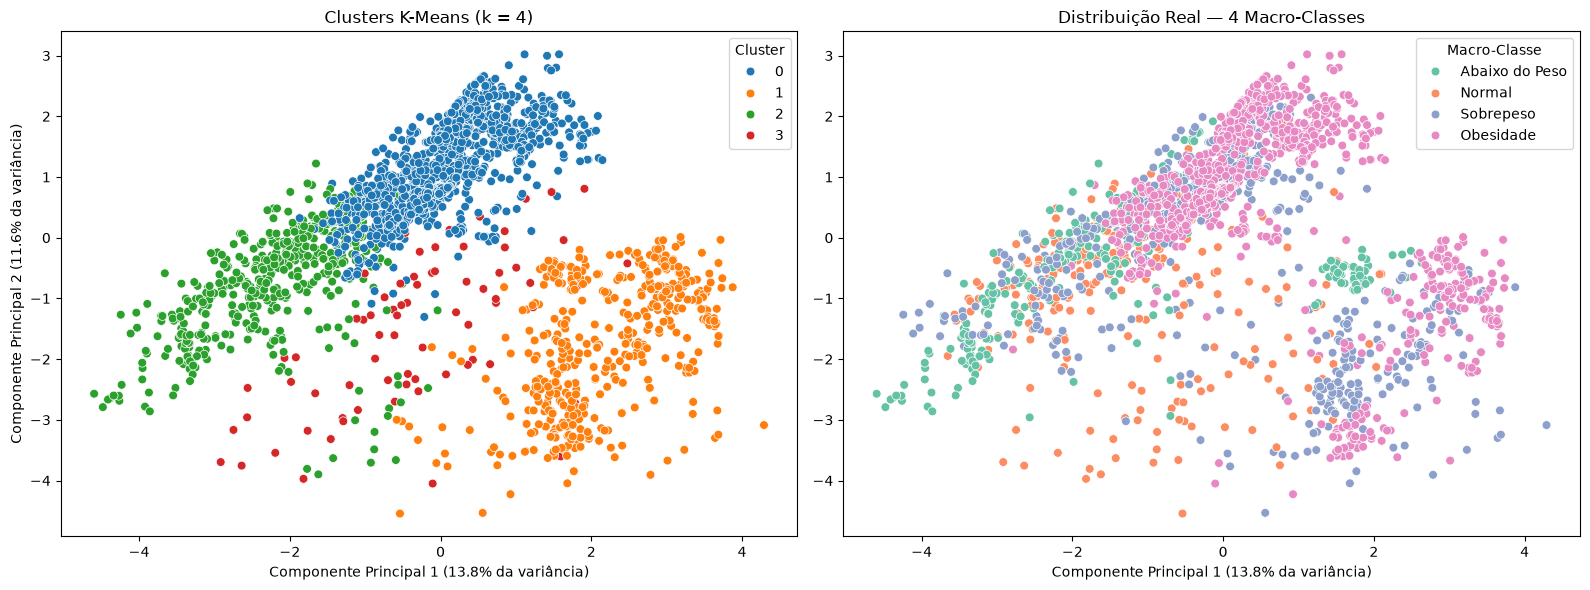

Composição dos clusters (k = 4 × 4 macro-classes):


macro-classe,Abaixo do Peso,Normal,Sobrepeso,Obesidade
cluster,,,,
0,28,44,275,751
1,45,33,159,206
2,188,164,113,8
3,6,41,19,7


Mapeamento cluster → macro-classe majoritária:


,macro-classe mapeada,tamanho,% da classe majoritária
0,Obesidade,1098,68.4
1,Obesidade,443,46.5
2,Abaixo do Peso,473,39.7
3,Normal,73,56.2


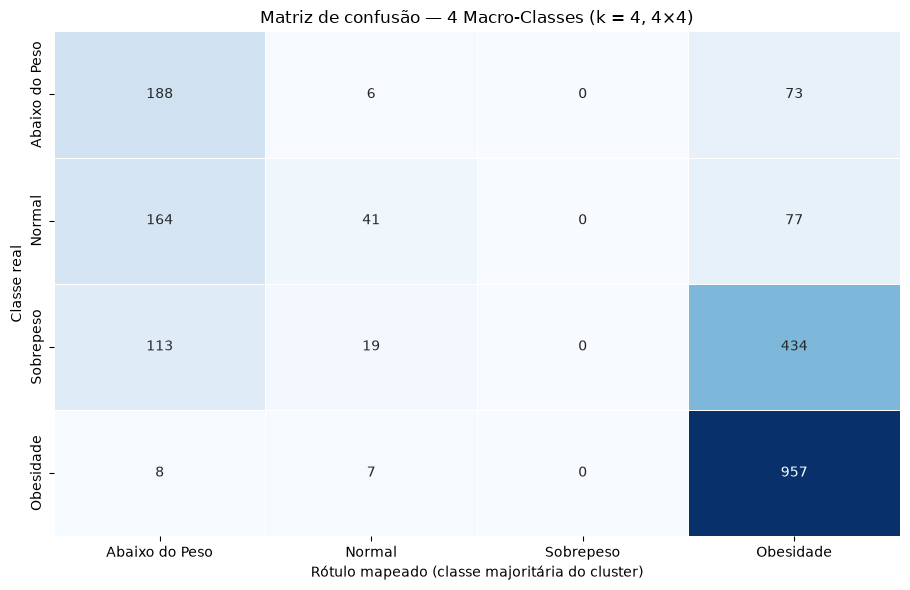

Acurácia (4 Macro-Classes, k = 4): 0.568 | Baseline (classe majoritária): 0.466


,suporte,previstos,acertos,precisao,recall
Abaixo do Peso,267,473,188,0.397,0.704
Normal,282,73,41,0.562,0.145
Sobrepeso,566,0,0,0.000,0.000
Obesidade,972,1541,957,0.621,0.985


In [10]:
# [IA] GitHub Copilot – agrupamento das 7 classes em 4 macro-classes, visualização PCA e métricas (4x4)
mapa_4classes = {
    "Insufficient_Weight": "Abaixo do Peso",
    "Normal_Weight": "Normal",
    "Overweight_Level_I": "Sobrepeso",
    "Overweight_Level_II": "Sobrepeso",
    "Obesity_Type_I": "Obesidade",
    "Obesity_Type_II": "Obesidade",
    "Obesity_Type_III": "Obesidade",
}
ordem_4classes = ["Abaixo do Peso", "Normal", "Sobrepeso", "Obesidade"]
y_4classes = y_real.map(mapa_4classes)

print("--- Distribuição das 4 macro-classes ---")
dist_4 = pd.DataFrame({
    "Contagem": y_4classes.value_counts().reindex(ordem_4classes),
    "Proporção (%)": (y_4classes.value_counts(normalize=True).reindex(ordem_4classes) * 100).round(2),
})
display(dist_4)

# Comparação visual no PCA: Clusters (k = 4) vs 4 Macro-Classes reais
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters_livre, palette="tab10", s=40, ax=axes[0])
axes[0].set_title(f"Clusters K-Means (k = {k_livre})")
axes[0].set_xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
axes[0].set_ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}% da variância)")
axes[0].legend(title="Cluster")

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y_4classes,
    hue_order=ordem_4classes,
    palette="Set2",
    s=40,
    ax=axes[1],
)
axes[1].set_title("Distribuição Real — 4 Macro-Classes")
axes[1].set_xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}% da variância)")
axes[1].set_ylabel("")
axes[1].legend(title="Macro-Classe")

plt.tight_layout()
plt.savefig(out_dir / "clusters_vs_4classes.png", dpi=150)
plt.show()

# Mapeamento cluster (k = 4) -> macro-classe majoritária
comp_4 = pd.crosstab(pd.Series(clusters_livre, name="cluster"), y_4classes.rename("macro-classe"))[ordem_4classes]
mapa_cluster_4 = comp_4.idxmax(axis=1).to_dict()
y_map_4 = pd.Series(clusters_livre).map(mapa_cluster_4)

print("Composição dos clusters (k = 4 × 4 macro-classes):")
display(comp_4)
print("Mapeamento cluster → macro-classe majoritária:")
display(pd.DataFrame({
    "macro-classe mapeada": mapa_cluster_4,
    "tamanho": comp_4.sum(axis=1),
    "% da classe majoritária": (comp_4.max(axis=1) / comp_4.sum(axis=1) * 100).round(1),
}))

# Matriz de confusão 4 × 4 e métricas
mc_4 = pd.DataFrame(
    confusion_matrix(y_4classes, y_map_4, labels=ordem_4classes),
    index=ordem_4classes,
    columns=ordem_4classes,
)
mc_4.index.name, mc_4.columns.name = "real", "mapeado"
mc_4.to_csv(out_dir / "matriz_confusao_4classes.csv")
plotar_matriz(mc_4, "Matriz de confusão — 4 Macro-Classes (k = 4, 4×4)", "matriz_confusao_4classes.png")

m4 = mc_4.to_numpy()
acertos_4 = np.diag(m4)
tot_col_4 = m4.sum(axis=0)
tot_lin_4 = m4.sum(axis=1)
prec_4 = np.divide(acertos_4, tot_col_4, out=np.zeros(len(acertos_4)), where=tot_col_4 > 0)
rec_4 = np.divide(acertos_4, tot_lin_4, out=np.zeros(len(acertos_4)), where=tot_lin_4 > 0)

met_4 = pd.DataFrame({
    "suporte": tot_lin_4,
    "previstos": tot_col_4,
    "acertos": acertos_4,
    "precisao": prec_4,
    "recall": rec_4,
}, index=ordem_4classes)
acc_4 = acertos_4.sum() / m4.sum()
baseline_4 = y_4classes.value_counts(normalize=True).max()
met_4.to_csv(out_dir / "metricas_4classes.csv")

print(f"Acurácia (4 Macro-Classes, k = 4): {acc_4:.3f} | Baseline (classe majoritária): {baseline_4:.3f}")
display(met_4.style.format({"precisao": "{:.3f}", "recall": "{:.3f}"}))

### 3.5 Verificação — por que a coluna "Sobrepeso" fica zerada na matriz 4×4

**Como a classe é "prevista" a partir do K-Means.** O K-Means não prevê classe: ele agrupa sem ver o rótulo `NObeyesdad`. Depois do agrupamento, cada cluster recebe o nome da classe real mais frequente dentro dele (mapeamento pela classe majoritária, como pede o enunciado), e todas as pessoas do cluster passam a ter esse rótulo previsto. A matriz de confusão compara esse rótulo previsto com a classe real.

**Por que Sobrepeso nunca é previsto.** Na composição acima, quase todas as pessoas com sobrepeso estão nos clusters 0 (275) e 1 (159), junto com a maior parte das pessoas com obesidade (751 e 206). Como Obesidade é 46,6% do dataset, ela é a maioria nos dois clusters, e os dois recebem o rótulo "Obesidade". Nenhum cluster fica com o rótulo "Sobrepeso", e a coluna inteira da matriz é zero. Não é erro de código: é uma consequência do mapeamento por maioria quando dois clusters têm a mesma classe dominante.

**Por que o K-Means não separou sobrepeso de obesidade.** A tabela abaixo cruza os clusters com o meio de transporte (`MTRANS`). Os clusters foram formados principalmente pelo transporte, e não pelo peso. Isso acontece porque, depois do One-Hot, `MTRANS` virou 5 colunas padronizadas; as categorias raras ganham valores muito altos (até 17 desvios-padrão em `MTRANS_Bike`), e uma única variável passa a ter o peso de cinco no cálculo da distância.

In [11]:
# [IA] Claude Code – cruzamento dos clusters com o meio de transporte (MTRANS) nas duas passadas
for nome, clusters in [(f"Passada 1 (k = {k_livre})", clusters_livre), (f"Passada 2 (k = {k_fixo})", clusters_fixo)]:
    tab = pd.crosstab(pd.Series(clusters, name="cluster"), df["MTRANS"])
    tab.to_csv(out_dir / f"clusters_vs_mtrans_k{len(tab)}.csv")
    print(f"{nome} — clusters × meio de transporte")
    display(tab)

Passada 1 (k = 4) — clusters × meio de transporte


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
cluster,,,,,
0,0,0,0,1098,0
1,443,0,0,0,0
2,13,0,0,460,0
3,0,7,11,0,55


Passada 2 (k = 7) — clusters × meio de transporte


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
cluster,,,,,
0,0,0,0,0,55
1,0,0,0,576,0
2,441,0,0,0,0
3,0,0,0,654,0
4,0,0,11,0,0
5,15,0,0,328,0
6,0,7,0,0,0


Na Passada 1, o cluster 0 é formado só por quem usa transporte público, o cluster 1 só por quem usa carro e o cluster 3 por quem anda a pé, de bicicleta ou de moto. Só o cluster 2 se separa por peso e altura (é o cluster de abaixo do peso e normal). Na Passada 2 o efeito é ainda mais forte: três clusters inteiros (0, 4 e 6) são só "a pé" (55 pessoas), "moto" (11) e "bicicleta" (7).

**Mapeamento alternativo um-para-um.** Para verificar se o problema está só no mapeamento, refizemos a matriz 4×4 obrigando cada cluster a receber uma macro-classe diferente. A atribuição que maximiza o total de acertos é encontrada pelo algoritmo húngaro (`scipy.optimize.linear_sum_assignment`). Esse mapeamento só é possível porque aqui o número de clusters (4) é igual ao número de macro-classes (4). Ele não substitui o mapeamento por maioria pedido no enunciado; é uma análise complementar.

Mapeamento cluster → macro-classe (um-para-um):


,por maioria,um-para-um,tamanho
0,Obesidade,Obesidade,1098
1,Obesidade,Sobrepeso,443
2,Abaixo do Peso,Abaixo do Peso,473
3,Normal,Normal,73


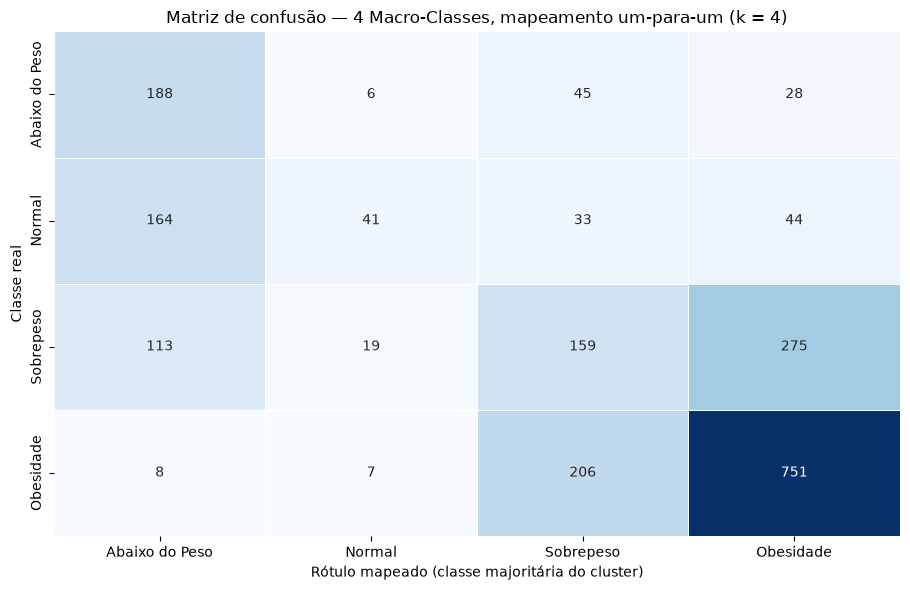

Acurácia por maioria: 0.568 | um-para-um: 0.546 | baseline: 0.466


,precisao (maioria),recall (maioria),precisao (um-para-um),recall (um-para-um)
Abaixo do Peso,0.397,0.704,0.397,0.704
Normal,0.562,0.145,0.562,0.145
Sobrepeso,0.000,0.000,0.359,0.281
Obesidade,0.621,0.985,0.684,0.773


In [12]:
# [IA] Claude Code – mapeamento um-para-um (algoritmo húngaro), matriz de confusão 4x4 e métricas
from scipy.optimize import linear_sum_assignment

linhas, colunas = linear_sum_assignment(-comp_4.to_numpy())   # negativo: maximizar acertos
mapa_hungaro = {comp_4.index[i]: ordem_4classes[j] for i, j in zip(linhas, colunas)}
y_map_hungaro = pd.Series(clusters_livre).map(mapa_hungaro)

print("Mapeamento cluster → macro-classe (um-para-um):")
display(pd.DataFrame({
    "por maioria": mapa_cluster_4,
    "um-para-um": mapa_hungaro,
    "tamanho": comp_4.sum(axis=1),
}))

mc_hungaro = pd.DataFrame(
    confusion_matrix(y_4classes, y_map_hungaro, labels=ordem_4classes),
    index=ordem_4classes, columns=ordem_4classes,
)
mc_hungaro.index.name, mc_hungaro.columns.name = "real", "mapeado"
mc_hungaro.to_csv(out_dir / "matriz_confusao_4classes_um_para_um.csv")
plotar_matriz(mc_hungaro, "Matriz de confusão — 4 Macro-Classes, mapeamento um-para-um (k = 4)",
              "matriz_confusao_4classes_um_para_um.png")

m = mc_hungaro.to_numpy()
acertos = np.diag(m)
met_hungaro = pd.DataFrame({
    "precisao (maioria)": met_4["precisao"],
    "recall (maioria)": met_4["recall"],
    "precisao (um-para-um)": acertos / m.sum(axis=0),
    "recall (um-para-um)": acertos / m.sum(axis=1),
}, index=ordem_4classes)
acc_hungaro = acertos.sum() / m.sum()
met_hungaro.to_csv(out_dir / "metricas_4classes_um_para_um.csv")

print(f"Acurácia por maioria: {acc_4:.3f} | um-para-um: {acc_hungaro:.3f} | baseline: {baseline_4:.3f}")
display(met_hungaro.round(3))

Com o mapeamento um-para-um, a classe Sobrepeso passa a aparecer na matriz (recall 0,28), ao custo de uma pequena queda na acurácia (de 0,568 para 0,546), porque o cluster 1, que era rotulado como Obesidade, agora é rotulado como Sobrepeso. Mesmo assim, a maior parte das pessoas com sobrepeso continua no cluster de Obesidade, o que confirma o diagnóstico: o problema principal não é o mapeamento, e sim que os clusters não separam sobrepeso de obesidade, porque foram formados principalmente pelo meio de transporte.

## 4. Discussão Crítica

### 4.1 Comparação quantitativa entre as passadas

Tabela de apoio para a discussão: métricas globais, métricas médias (macro) e quantas classes reais cada passada consegue representar. Como referência, incluímos a acurácia de um classificador trivial que sempre prevê a classe mais frequente.

Acurácia do baseline (sempre a classe mais frequente): 0.168


,k,acurácia,precisão macro,recall macro,classes representadas,clusters com mesmo rótulo
passada,,,,,,
1 — k livre,4,0.317,0.215,0.309,4/7,0
2 — k fixo,7,0.306,0.256,0.299,5/7,2


,recall P1 (k livre),recall P2 (k fixo),precisão P1,precisão P2
Insufficient_Weight,0.704,0.528,0.397,0.411
Normal_Weight,0.145,0.145,0.562,0.562
Overweight_Level_I,0.000,0.000,0.000,0.000
Overweight_Level_II,0.000,0.000,0.000,0.000
Obesity_Type_I,0.313,0.313,0.248,0.249
Obesity_Type_II,0.000,0.498,0.000,0.226
Obesity_Type_III,0.997,0.611,0.294,0.344


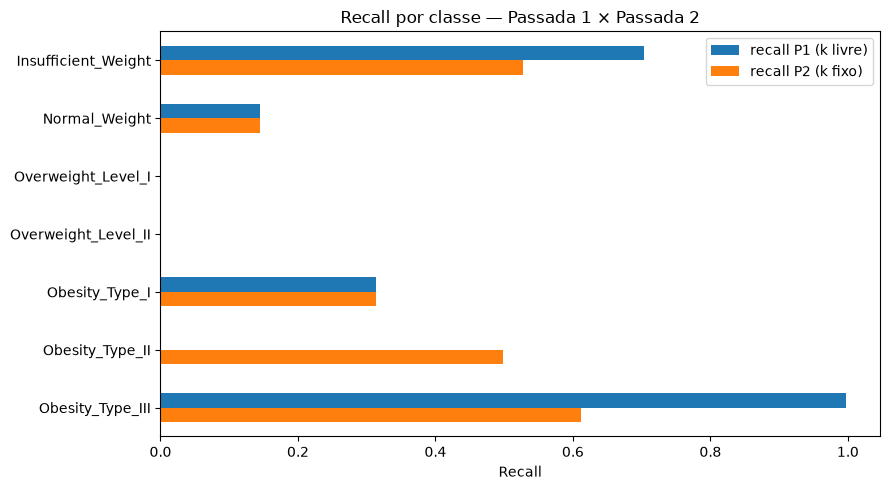

In [13]:
# [IA] Claude Code – tabela comparativa das duas passadas e recall por classe lado a lado
baseline = y_real.value_counts(normalize=True).max()

def resumo(nome, k, acc, met, mapa):
    representadas = len(set(mapa.values()))
    return {
        "passada": nome,
        "k": k,
        "acurácia": acc,
        "precisão macro": met["precisao"].mean(),
        "recall macro": met["recall"].mean(),
        "classes representadas": f"{representadas}/{len(ordem_classes)}",
        "clusters com mesmo rótulo": k - representadas,
    }

comparacao = pd.DataFrame([
    resumo("1 — k livre", k_livre, acc_livre, met_livre, mapa_livre),
    resumo("2 — k fixo", k_fixo, acc_fixo, met_fixo, mapa_fixo),
]).set_index("passada")
comparacao.to_csv(out_dir / "comparacao_passadas.csv")
print(f"Acurácia do baseline (sempre a classe mais frequente): {baseline:.3f}")
display(comparacao.style.format({"acurácia": "{:.3f}", "precisão macro": "{:.3f}", "recall macro": "{:.3f}"}))

recall_lado_a_lado = pd.DataFrame({
    "recall P1 (k livre)": met_livre["recall"],
    "recall P2 (k fixo)": met_fixo["recall"],
    "precisão P1": met_livre["precisao"],
    "precisão P2": met_fixo["precisao"],
})
display(recall_lado_a_lado.round(3))

ax = recall_lado_a_lado[["recall P1 (k livre)", "recall P2 (k fixo)"]].plot.barh(figsize=(9, 5))
ax.set_xlabel("Recall")
ax.set_title("Recall por classe — Passada 1 × Passada 2")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(out_dir / "recall_comparacao.png", dpi=150)
plt.show()

### 4.2 Discussão

**Qual passada gerou grupos mais coerentes?**

As duas passadas ficaram muito próximas, e nenhuma reproduz bem as 7 classes. A Passada 1 (k = 4) teve acurácia um pouco maior (0,317 contra 0,306) e recall médio um pouco maior (0,309 contra 0,299); a Passada 2 (k = 7) teve precisão média maior (0,256 contra 0,215) e representa 5 das 7 classes, contra 4. As duas superam o baseline de 0,168 (prever sempre a classe mais frequente), então os clusters carregam alguma informação sobre o nível de obesidade, mas pouca: cerca de 7 em cada 10 pessoas caem num cluster cuja classe majoritária não é a sua.

Consideramos a Passada 1 a mais coerente. Com quase o mesmo desempenho, ela usa menos grupos, e seus 4 clusters têm tamanhos razoáveis. Na Passada 2, os 3 clusters a mais não foram usados para separar níveis de obesidade: três deles (0, 4 e 6) têm só 55, 11 e 7 pessoas e são formados, respectivamente, só por quem anda a pé, de moto e de bicicleta (seção 3.5), e os três receberam o rótulo `Normal_Weight`. O único ganho real da Passada 2 é separar `Obesity_Type_II` de `Obesity_Type_III` (recall de `Obesity_Type_II` vai de 0 para 0,498), e essa separação veio do sexo, como mostrado abaixo.

**Por que algumas classes nunca são previstas?**

No mapeamento pela classe majoritária, cada cluster recebe o nome da classe real mais frequente dentro dele, e vários clusters podem receber o mesmo nome. Na Passada 2, três clusters viraram `Normal_Weight`, e sobram só 5 rótulos distintos; `Overweight_Level_I` e `Overweight_Level_II` nunca são previstas (recall 0 nas duas passadas). Essas pessoas estão espalhadas: na Passada 2, `Overweight_Level_II` aparece com 71, 94 e 106 registros nos clusters 1, 2 e 3, e em nenhum deles é maioria. As faixas de sobrepeso ficam no meio da escala de IMC e se sobrepõem às classes vizinhas.

O mesmo acontece na análise com 4 macro-classes (seção 3.4): os clusters 0 e 1 têm maioria de Obesidade (Obesidade é 46,6% do dataset), os dois recebem esse rótulo e a coluna "Sobrepeso" da matriz fica zerada. Com o mapeamento um-para-um (seção 3.5), Sobrepeso passa a aparecer (recall 0,28), mas a acurácia cai de 0,568 para 0,546 e a maior parte das pessoas com sobrepeso continua no cluster de Obesidade. Ou seja, o mapeamento explica a coluna zerada, mas a causa de fundo é que os clusters não separam sobrepeso de obesidade.

**O que o K-Means realmente agrupou**

- *Meio de transporte:* é o eixo principal. Na Passada 1, o cluster 0 é 100% transporte público, o cluster 1 é 100% carro e o cluster 3 reúne a pé, bicicleta e moto. Na Passada 2 cada cluster tem praticamente um único meio de transporte. Isso acontece porque, depois do One-Hot e da padronização, `MTRANS` virou 5 colunas, e as categorias raras ganharam valores muito altos (até 17 desvios-padrão em `MTRANS_Bike`), então uma variável pesa como cinco na distância.
- *Sexo/altura:* na Passada 2, os clusters 1 e 3 são ambos de transporte público, mas o cluster 1 tem 83% de mulheres e altura média de 1,64 m, e o cluster 3 tem 21% de mulheres e 1,78 m. O cluster feminino fica com maioria `Obesity_Type_III` e o masculino com `Obesity_Type_II`. Como o IMC é peso dividido pela altura ao quadrado, a separação entre esses níveis veio do sexo, não de um grau maior de obesidade.
- *Histórico familiar e idade:* o cluster 5 da Passada 2, de maioria `Insufficient_Weight`, é o único em que poucos têm histórico familiar de sobrepeso (12%, contra 55% a 100% nos demais), e o cluster 2 (carro) é o mais velho (idade média de 32 anos).

Ou seja, o K-Means encontrou perfis de estilo de vida e de corpo, que é o que as 20 variáveis descrevem com peso igual, enquanto as classes reais foram definidas a partir de apenas duas delas (peso e altura, via IMC).

**Granularidade das classes**

As classes foram criadas a partir do IMC (segundo a documentação do dataset, com base nas faixas da OMS e da normativa mexicana), mas nos dados elas não funcionam como cortes limpos de uma única variável. A tabela de IMC por classe (seção 3.3) mostra que as faixas de classes vizinhas se sobrepõem: por exemplo, sobrepeso I vai de 22,8 a 28,8 e sobrepeso II de 25,7 a 30,4, e o IMC mínimo de sobrepeso I (22,8) fica dentro da faixa de peso normal (18,5 a 24,9). Uma explicação provável é que cerca de 77% dos registros foram gerados sinteticamente (SMOTE), por interpolação entre registros, o que pode criar combinações de peso e altura fora da faixa da própria classe. Com isso, nem o IMC sozinho separa perfeitamente as classes vizinhas, e o K-Means tem ainda menos chance, porque as outras 18 variáveis, padronizadas com o mesmo peso, diluem a informação de peso e altura.

O agrupamento em 4 macro-classes confirma que uma divisão mais grosseira combina melhor com os dados: com k = 4, a acurácia sobe para 0,568 (baseline 0,466), contra 0,317 nas 7 classes. Mesmo assim, Normal (recall 0,145) e Sobrepeso continuam mal separados, porque ficam no meio da escala e se misturam com as classes vizinhas.

**Limitações**

- A codificação One-Hot de `MTRANS`, padronizada junto com as outras variáveis, fez o transporte dominar o agrupamento. Uma alternativa seria dar menos peso a essas colunas ou não padronizar as variáveis binárias.
- Cerca de 77% do dataset foi gerado sinteticamente (SMOTE) pelos autores. Isso explica valores fracionários em variáveis que deveriam ser discretas (`FCVC`, `NCP`, `FAF`, `TUE`, `CH2O`) e pode criar padrões artificiais.
- A escolha de k = 4 foi feita pelo cotovelo, que não tem um ponto de inflexão claro.
- O mapeamento pela classe majoritária permite que vários clusters recebam o mesmo rótulo e deixa classes sem representação, o que penaliza as métricas por classe.
- O K-Means assume grupos esféricos e de tamanho parecido, o que não vale aqui: na Passada 2 há clusters de 7 e de 654 pessoas.